# 01 — Exploration des données

Exploration conservée depuis le notebook d’origine.

In [5]:
from pathlib import Path
import sys

RACINE = Path.cwd().resolve()
if RACINE.name == 'notebooks':
    RACINE = RACINE.parent
sys.path.insert(0, str(RACINE))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
import prince  # Bibliothèque pour ACM / MCA, faire pip install --upgrade prince scikit-learn pandas numpy si nécessaire

# pip install fastcluster
import fastcluster
from scipy.cluster.hierarchy import dendrogram, fcluster
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin, silhouette_score

from itertools import combinations
from IPython.display import display

In [8]:
# Charger le jeu de données depuis le dossier data
chemin_fichier = str(RACINE / "data/brutes/td_clustering_karafun.csv")
data = pd.read_csv(chemin_fichier)

# Structure et dimensions
print(data.info())
print("Lignes et colonnes :", data.shape)

# Valeurs nulles
print(data.isnull().sum())

# Valeurs dupliquées
print("Valeurs dupliquées :", data.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 341092 entries, 0 to 341091
Data columns (total 16 columns):
 #   Column                      Non-Null Count   Dtype
---  ------                      --------------   -----
 0   id_anonyme                  341092 non-null  str  
 1   anciennete_client_tr        341092 non-null  str  
 2   anciennete_abonnement_tr    341092 non-null  str  
 3   statut_abonnement           341092 non-null  str  
 4   type_client                 341092 non-null  str  
 5   type_very_first_abo         341092 non-null  str  
 6   type_first_abo_last_streak  341092 non-null  str  
 7   ratio_fidelite_tr           341092 non-null  str  
 8   methode_paiement            341092 non-null  str  
 9   nb_abo_periode              341092 non-null  int64
 10  valeur_12M_tr               341092 non-null  str  
 11  avg_sessions_actifs_tr      341092 non-null  str  
 12  avg_songs_sessions_tr       341092 non-null  str  
 13  utilise_remote              341092 non-null  str  
 14 

In [9]:
cat_cols = [
    'anciennete_client_tr',
    'anciennete_abonnement_tr',
    'statut_abonnement',
    'type_client',
    'type_very_first_abo',
    'type_first_abo_last_streak',
    'ratio_fidelite_tr',
    'methode_paiement',
    'valeur_12M_tr',
    'avg_sessions_actifs_tr',
    'avg_songs_sessions_tr',
    'utilise_remote',
    'zone_geo',
    'contactable'
]

for col in cat_cols:
    print(f"--- Distribution de {col} ---")
    print(data[col].value_counts(dropna=False))
    print(data) # Pourcentage
    print("\n")

--- Distribution de anciennete_client_tr ---
anciennete_client_tr
07_7a9_mois            35479
06_6_mois              32676
08_10a12_mois          30305
13_25a30_mois          24140
15_37a48_mois          21919
10_16a18_mois          21789
14_31a36_mois          17481
09_13a15_mois          16764
17_61a84_mois          15077
18_85a120_mois         13940
11_19a21_mois          13268
01_1_mois              12680
00_moins_1_mois        12474
05_5_mois              12310
16_49a60_mois          12168
12_22a24_mois          11110
02_2_mois              10455
03_3_mois              10085
04_4_mois               9835
19_121_mois_et_plus     7137
Name: count, dtype: int64
                                               id_anonyme  \
0       fbb58c58395ab62899c58d6a52f8159ca12ddd7f46bfe2...   
1       8c981dbb88db4abcfd1c07b30ec42c370195fabaf74b8a...   
2       a4b6c3d31fb413aa830dbb423bd3d8446438dae71d9973...   
3       ef9a45455295911d59cd8a9c76d32d582709e40a5a238f...   
4       91d37bd372c738e

In [10]:
# Stats desc générales
print(data[['nb_abo_periode']].describe())

# Mode et Médiane
print("Médiane:", data['nb_abo_periode'].median())
print("Mode:", data['nb_abo_periode'].mode()[0])

       nb_abo_periode
count   341092.000000
mean         5.454860
std          4.356785
min          1.000000
25%          1.000000
50%          4.000000
75%         10.000000
max         12.000000
Médiane: 4.0
Mode: 1


C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


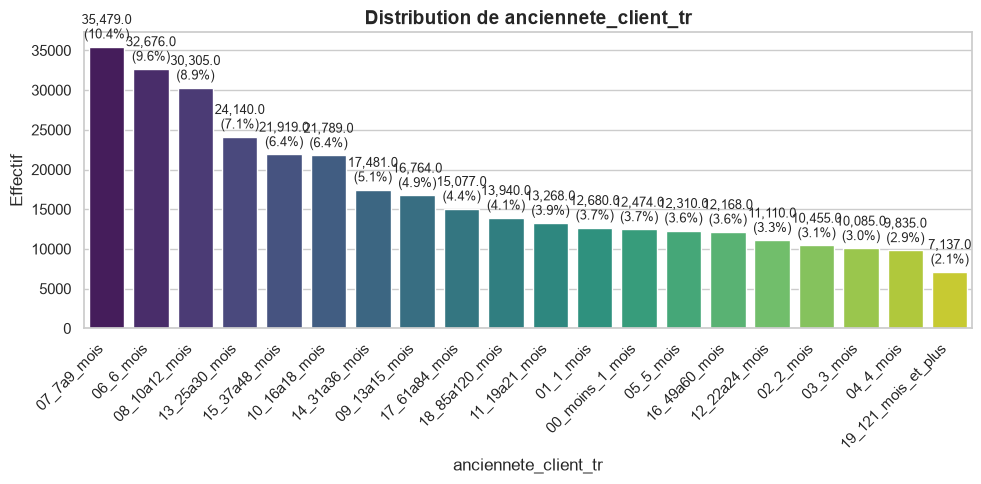

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


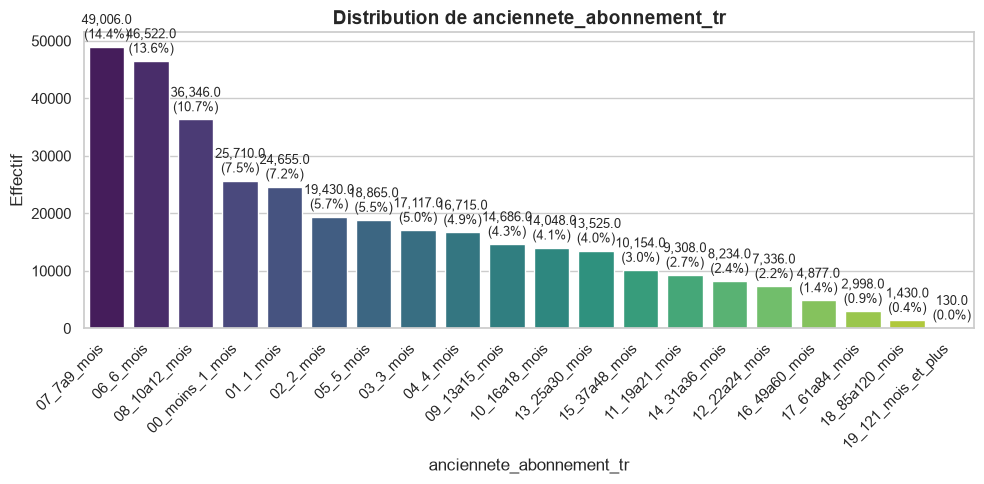

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


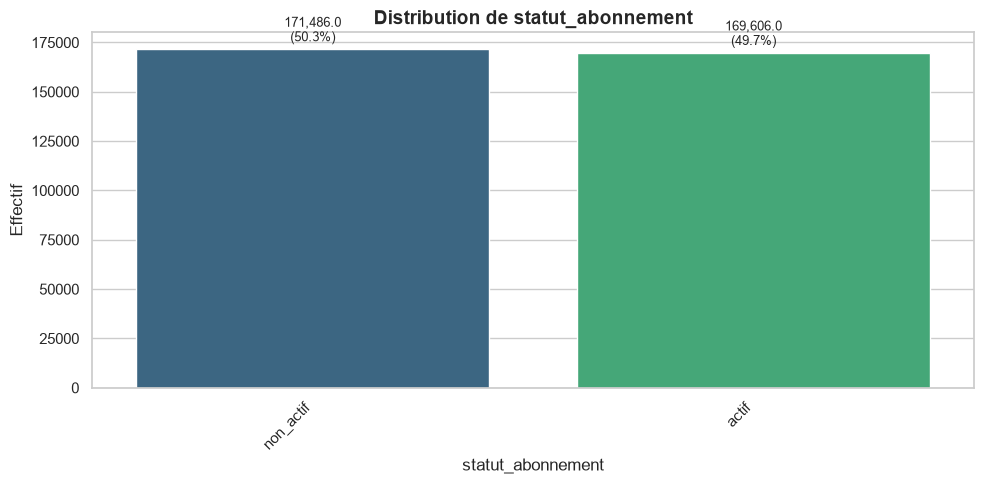

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


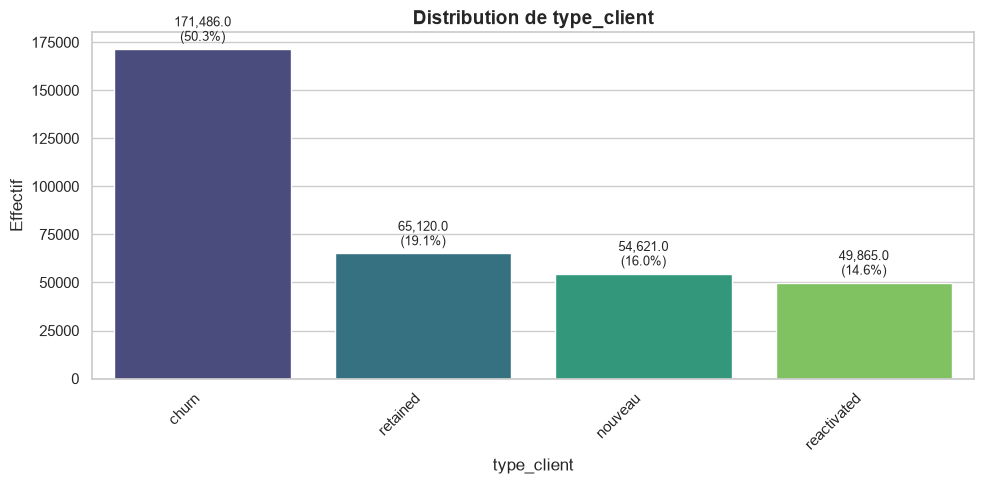

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


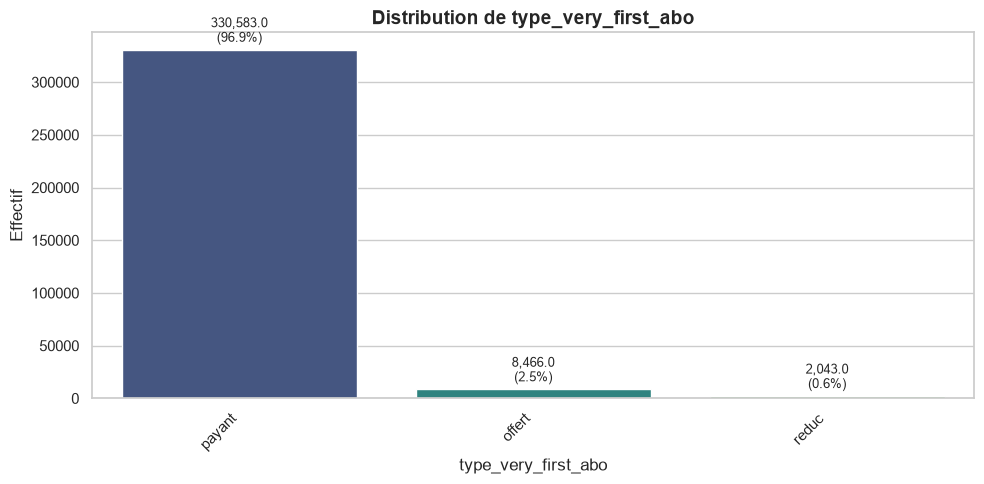

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


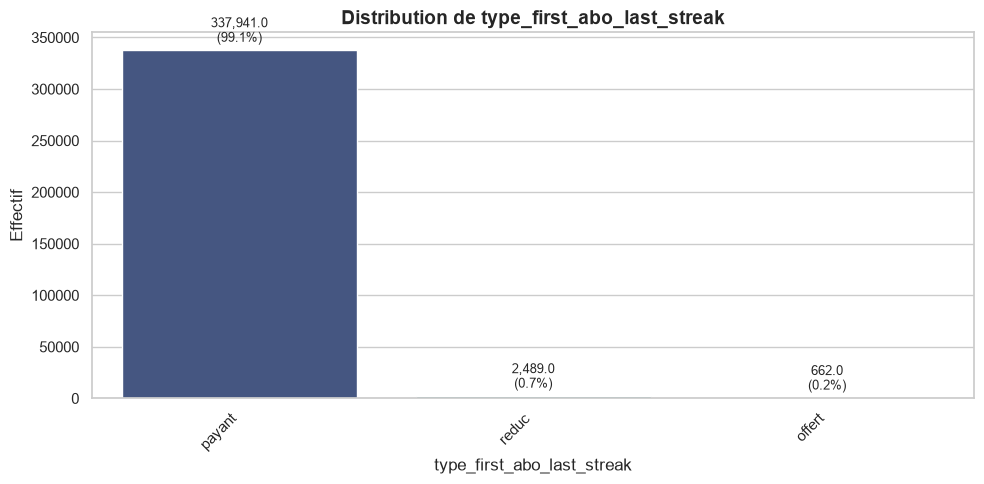

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


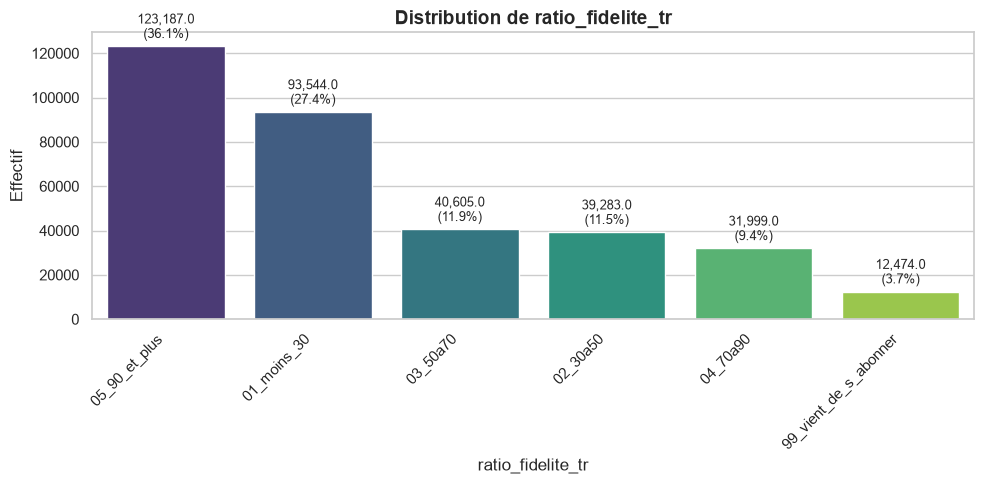

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


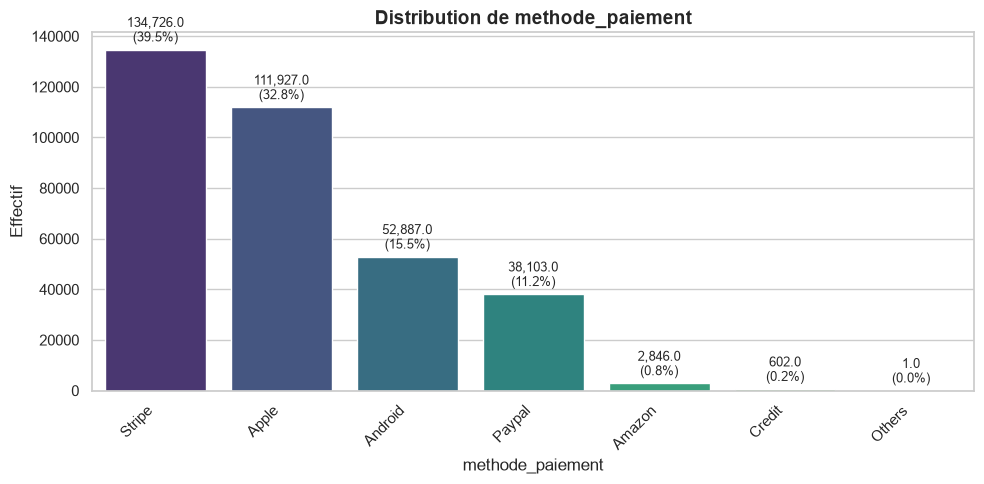

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


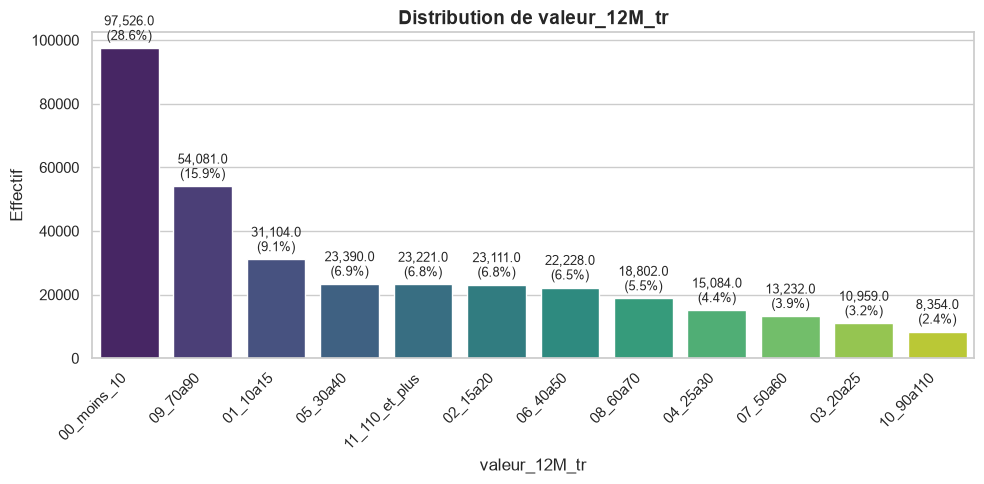

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


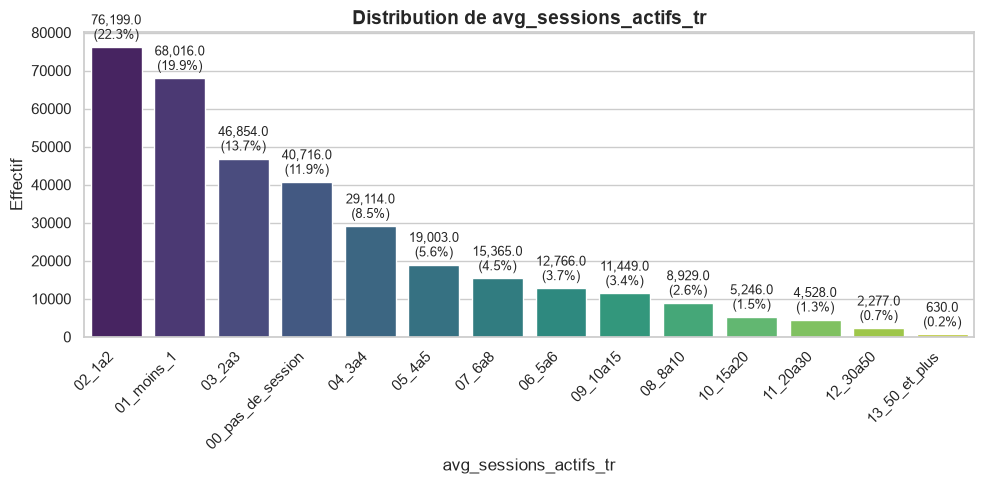

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


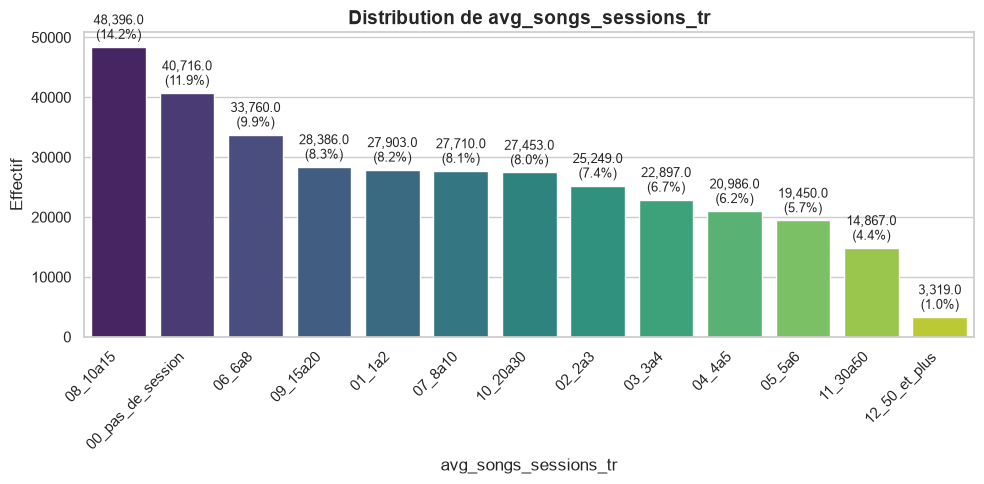

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


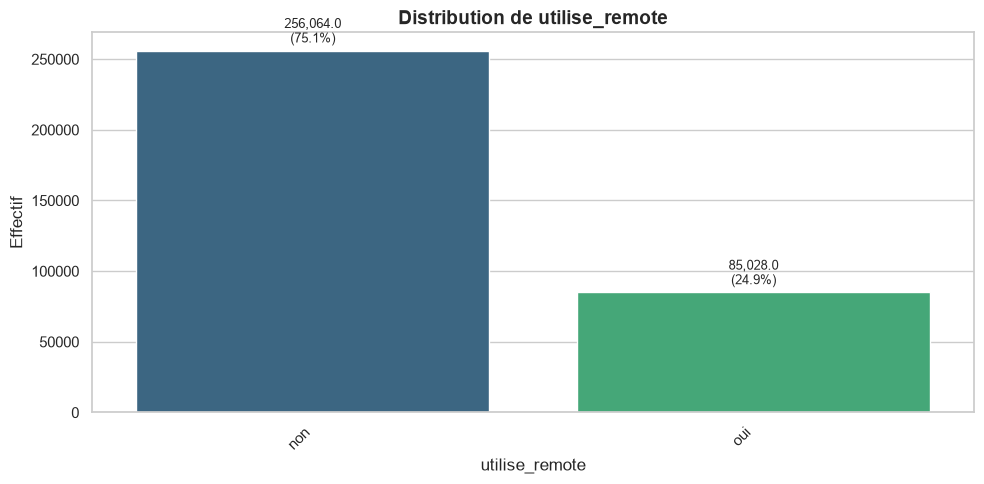

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


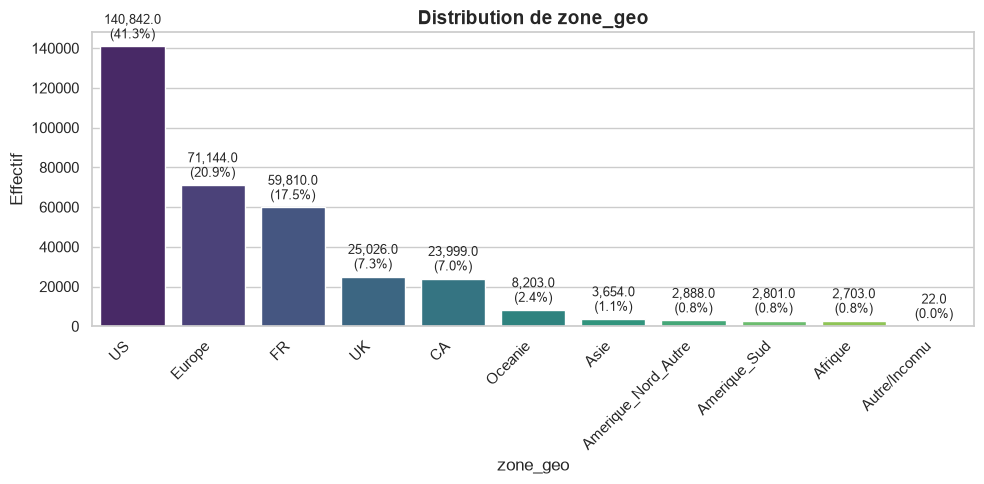

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4264730040.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x=col, order=order, palette="viridis")


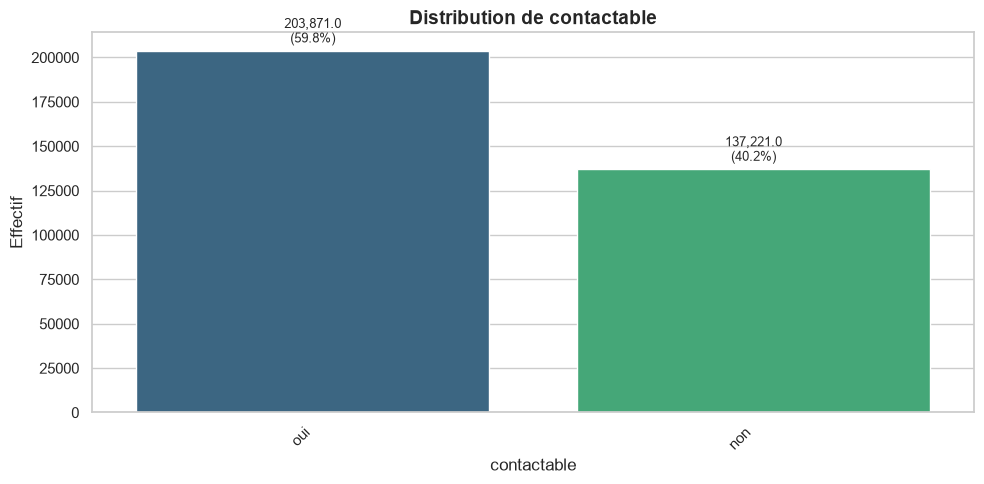

In [11]:
# Configuration du style des graphiques
sns.set_theme(style="whitegrid")

# Graphiques de distribution pour chaque variable catégorielle
for col in cat_cols:
    plt.figure(figsize=(10, 5))
    
    # Calcul des fréquences pour ordonner les barres
    order = data[col].value_counts().index
    
    # Création du barplot
    ax = sns.countplot(data=data, x=col, order=order, palette="viridis")
    
    # Ajout des pourcentages au-dessus de chaque barre
    total = len(data[col])
    for p in ax.patches:
        height = p.get_height()
        percentage = f'{100 * height / total:.1f}%'
        ax.annotate(f'{height:,}\n({percentage})', 
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                    textcoords='offset points')
        
    plt.title(f"Distribution de {col}", fontsize=14, fontweight='bold')
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Effectif", fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

In [12]:
# Génération d'une table de fréquences pour chaque variable
tables_frequences = {}

for col in cat_cols:
    # Calcul des fréquences absolues et relatives
    counts = data[col].value_counts(dropna=False)
    percentages = data[col].value_counts(normalize=True, dropna=False) * 100
    
    # Création du DataFrame récapitulatif
    df_freq = pd.DataFrame({
        'Modalité': counts.index,
        'Effectif': counts.values,
        'Pourcentage (%)': percentages.values.round(2)
    })
    
    tables_frequences[col] = df_freq
    
    print(f"=== Table de fréquence : {col} ===")
    print(df_freq.to_string(index=False))
    print("\n" + "="*40 + "\n")

=== Table de fréquence : anciennete_client_tr ===
           Modalité  Effectif  Pourcentage (%)
        07_7a9_mois     35479            10.40
          06_6_mois     32676             9.58
      08_10a12_mois     30305             8.88
      13_25a30_mois     24140             7.08
      15_37a48_mois     21919             6.43
      10_16a18_mois     21789             6.39
      14_31a36_mois     17481             5.13
      09_13a15_mois     16764             4.91
      17_61a84_mois     15077             4.42
     18_85a120_mois     13940             4.09
      11_19a21_mois     13268             3.89
          01_1_mois     12680             3.72
    00_moins_1_mois     12474             3.66
          05_5_mois     12310             3.61
      16_49a60_mois     12168             3.57
      12_22a24_mois     11110             3.26
          02_2_mois     10455             3.07
          03_3_mois     10085             2.96
          04_4_mois      9835             2.88
19_121_moi

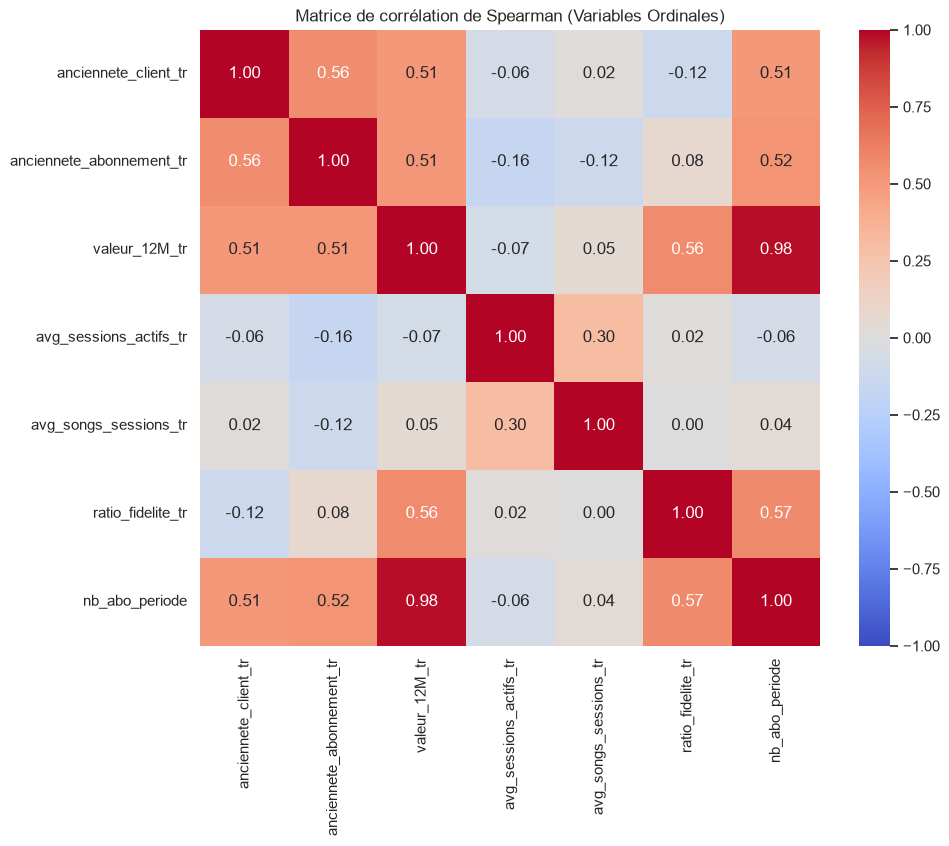

In [13]:
# Variables ordinales et discretes
cols_ordinales = [
    'anciennete_client_tr', 'anciennete_abonnement_tr', 
    'valeur_12M_tr', 'avg_sessions_actifs_tr', 
    'avg_songs_sessions_tr', 'ratio_fidelite_tr'
]

df_corr = data[cols_ordinales + ['nb_abo_periode']].copy()

for col in cols_ordinales:
    df_corr[col] = df_corr[col].astype('category').cat.codes

# Matrice
corr_matrix = df_corr.corr(method='spearman')

# 4. Visualization
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Matrice de corrélation de Spearman (Variables Ordinales)")
plt.show()

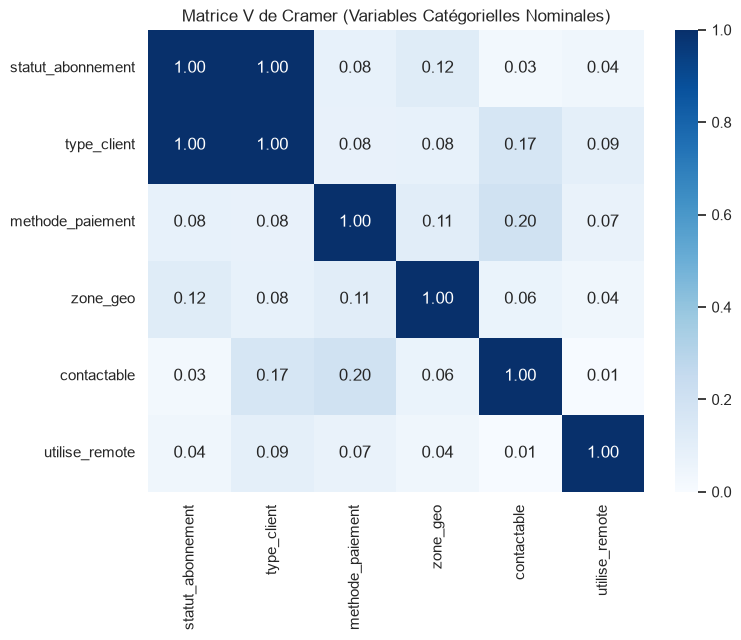

In [14]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    if min((kcorr-1), (rcorr-1)) == 0:
        return 0.0
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# Colonnes catégorielles nominales
cols_nominales = ['statut_abonnement', 'type_client', 'methode_paiement', 'zone_geo', 'contactable', 'utilise_remote']

# Matrice V de Cramer
v_matrix = pd.DataFrame(index=cols_nominales, columns=cols_nominales, dtype=float)

for col1 in cols_nominales:
    for col2 in cols_nominales:
        v_matrix.loc[col1, col2] = cramers_v(data[col1], data[col2])

# Visualization
plt.figure(figsize=(8, 6))
sns.heatmap(v_matrix, annot=True, cmap='Blues', vmin=0, vmax=1, fmt=".2f")
plt.title("Matrice V de Cramer (Variables Catégorielles Nominales)")
plt.show()

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\3789934901.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dist_globale.index, y=dist_globale.values, palette='Blues_d')


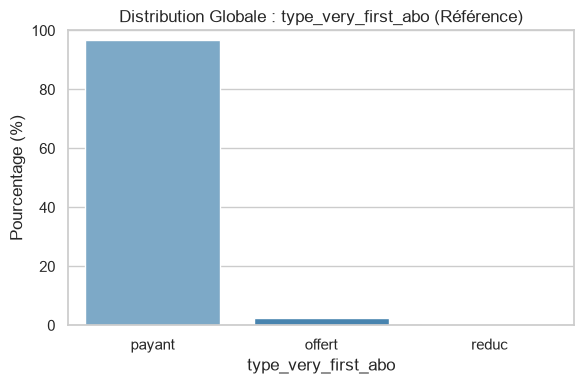

c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the s

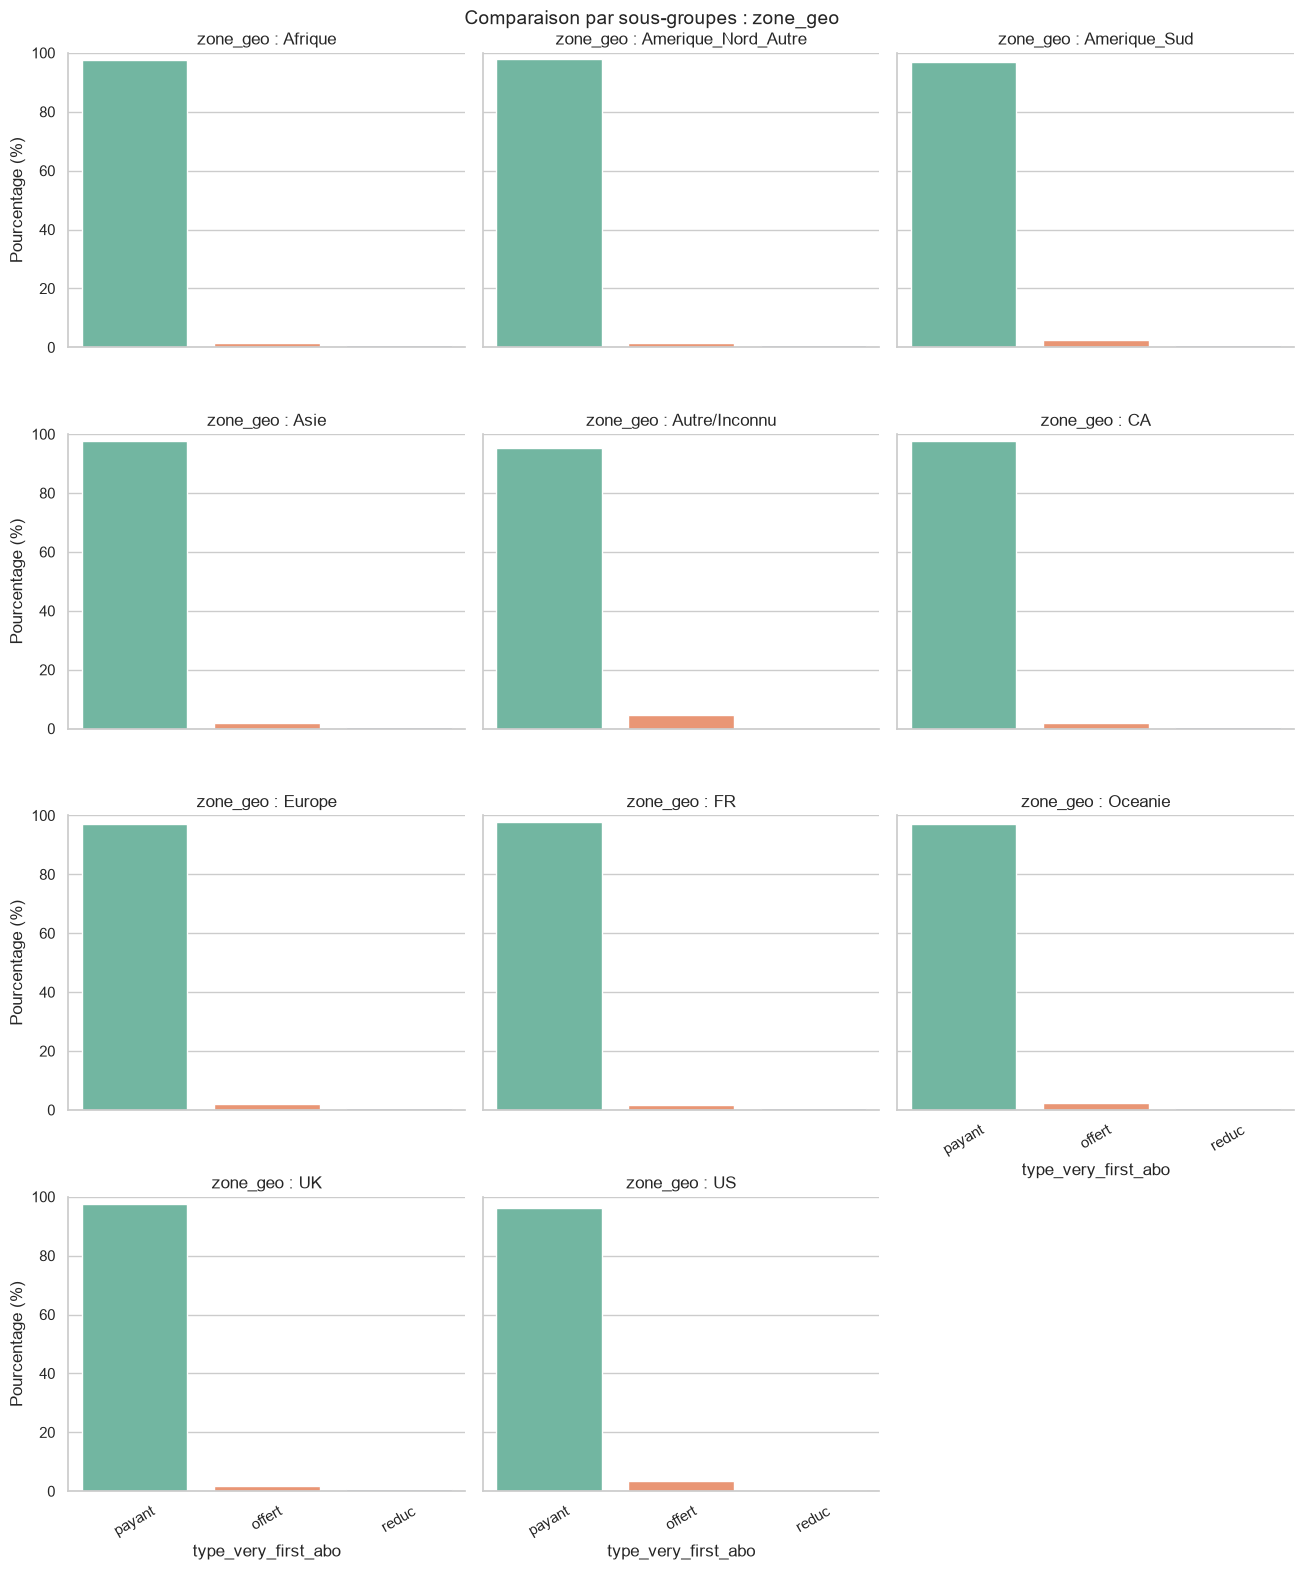

c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the s

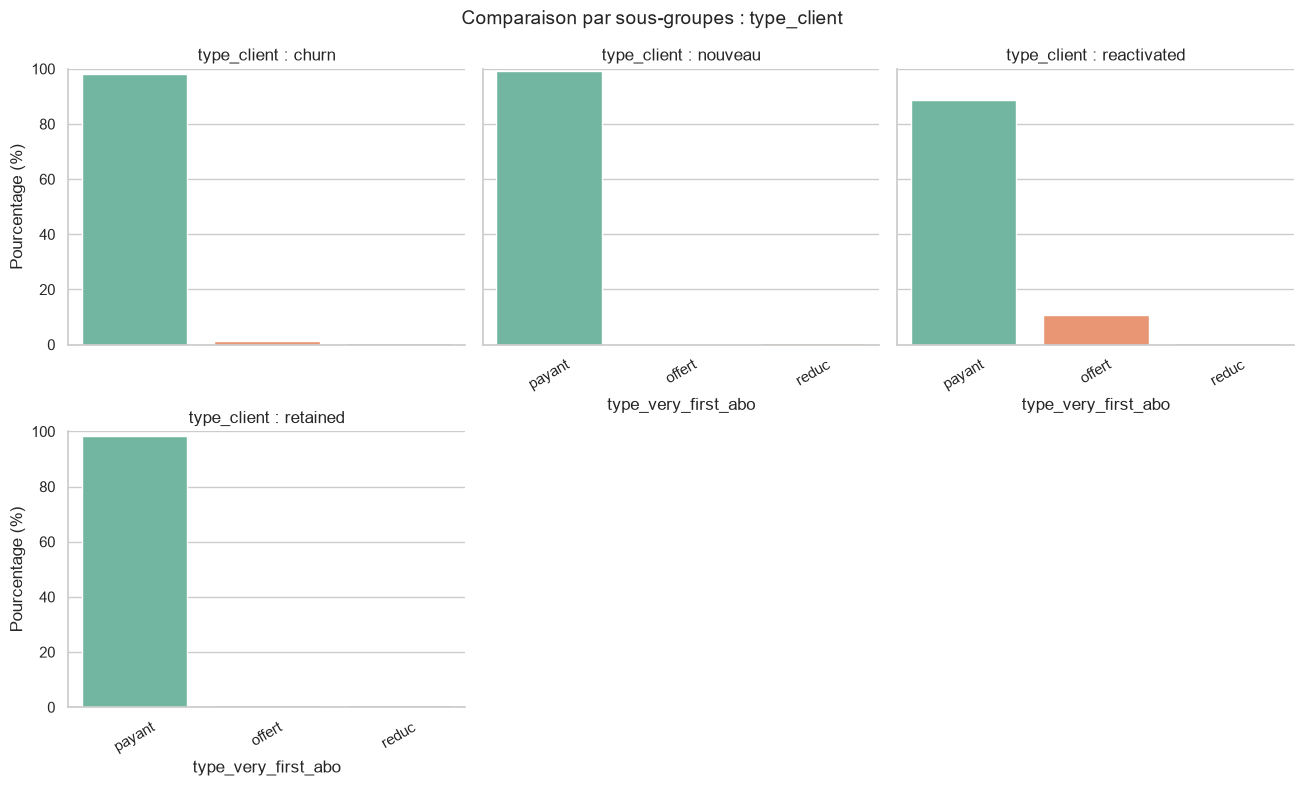

c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the s

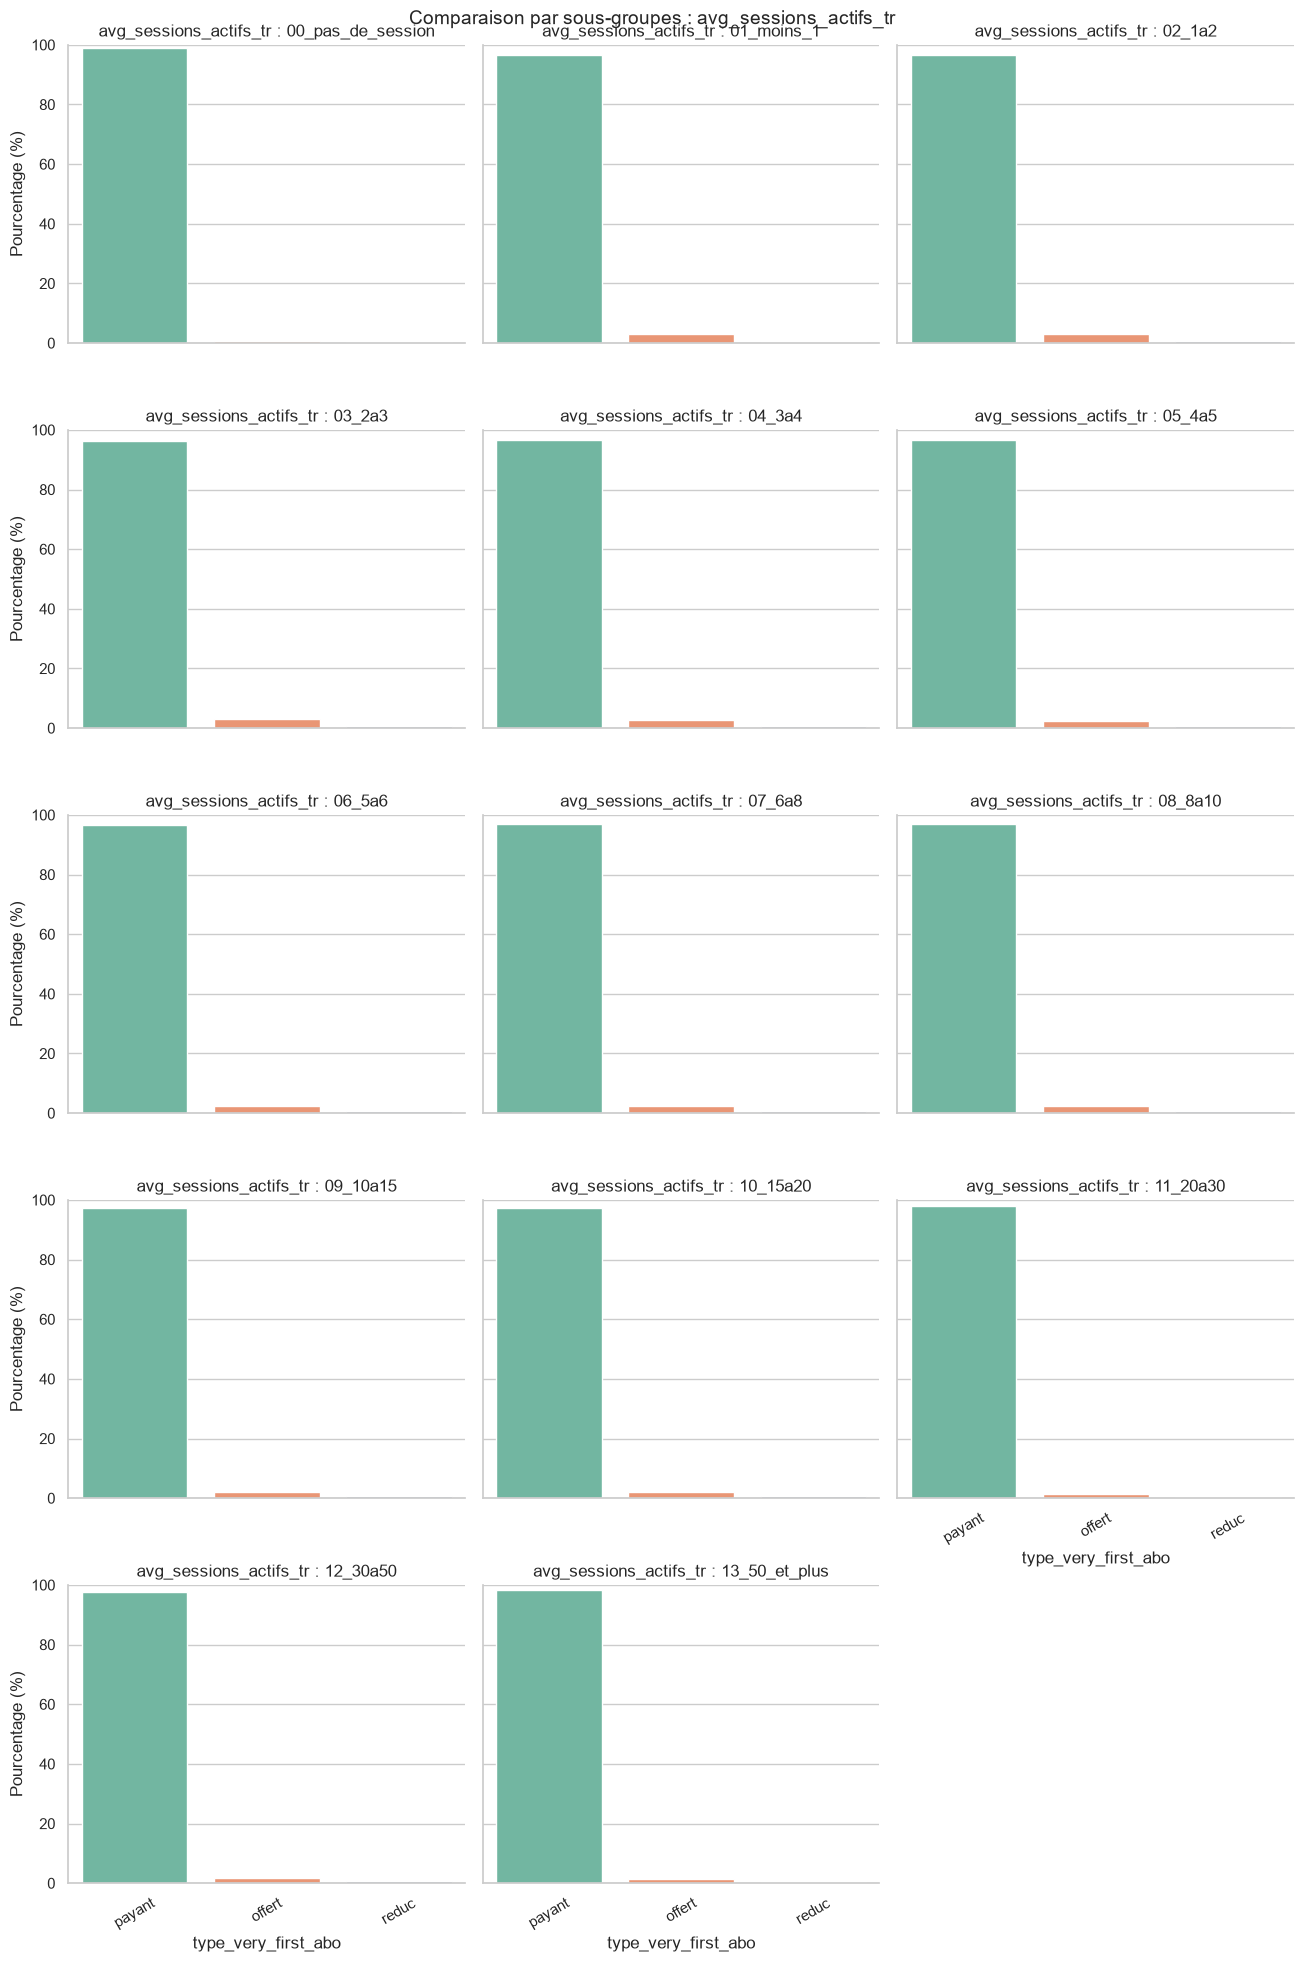

In [15]:
# 1. Calcul de la distribution globale de référence (type_very_first_abo)
dist_globale = data['type_very_first_abo'].value_counts(normalize=True) * 100

# Affichage du graphique de référence
plt.figure(figsize=(6, 4))
sns.barplot(x=dist_globale.index, y=dist_globale.values, palette='Blues_d')
plt.title('Distribution Globale : type_very_first_abo (Référence)')
plt.ylabel('Pourcentage (%)')
plt.xlabel('type_very_first_abo')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# 2. Liste des variables à analyser
liste_variables = ['zone_geo', 'type_client', 'avg_sessions_actifs_tr']

# 3. Boucle d'itération sur chaque variable
for var in liste_variables:
    # Calcul des proportions relatives pour la variable actuelle
    df_prop = (
        data.groupby(var)['type_very_first_abo']
        .value_counts(normalize=True)
        .rename('pourcentage')
        .reset_index()
    )
    df_prop['pourcentage'] *= 100
    
    # Création de la grille de sous-graphiques (FacetGrid)
    # col_wrap=3 permet d'afficher 3 graphiques par ligne au maximum
    g = sns.FacetGrid(df_prop, col=var, col_wrap=3, height=4, aspect=1.1)
    g.map_dataframe(sns.barplot, x='type_very_first_abo', y='pourcentage', palette='Set2')
    
    # Personnalisation visuelle de la grille
    g.set_axis_labels('type_very_first_abo', 'Pourcentage (%)')
    g.set_titles(col_template=f'{var} : {{col_name}}')
    g.set(ylim=(0, 100))  # Maintien de l'échelle fixe à 100%
    
    # Rotation des étiquettes si le texte sur l'axe X est trop long
    for ax in g.axes.flat:
        ax.tick_params(axis='x', rotation=30)
        
    g.fig.subplots_adjust(top=0.85)
    g.fig.suptitle(f'Comparaison par sous-groupes : {var}', fontsize=14)
    plt.tight_layout()
    plt.show()

C:\Users\SebastianAraya\AppData\Local\Temp\ipykernel_23628\4200297218.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dist_globale_paiement.index, y=dist_globale_paiement.values, palette='Blues_d')


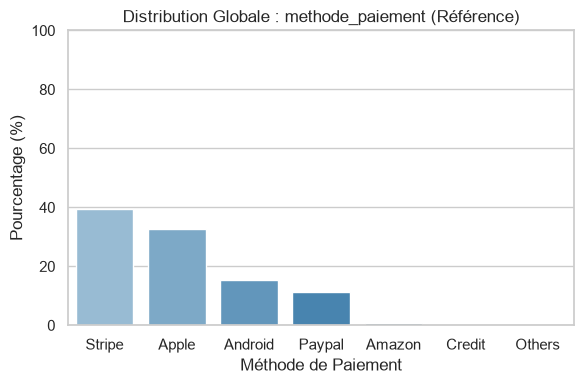

c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the s

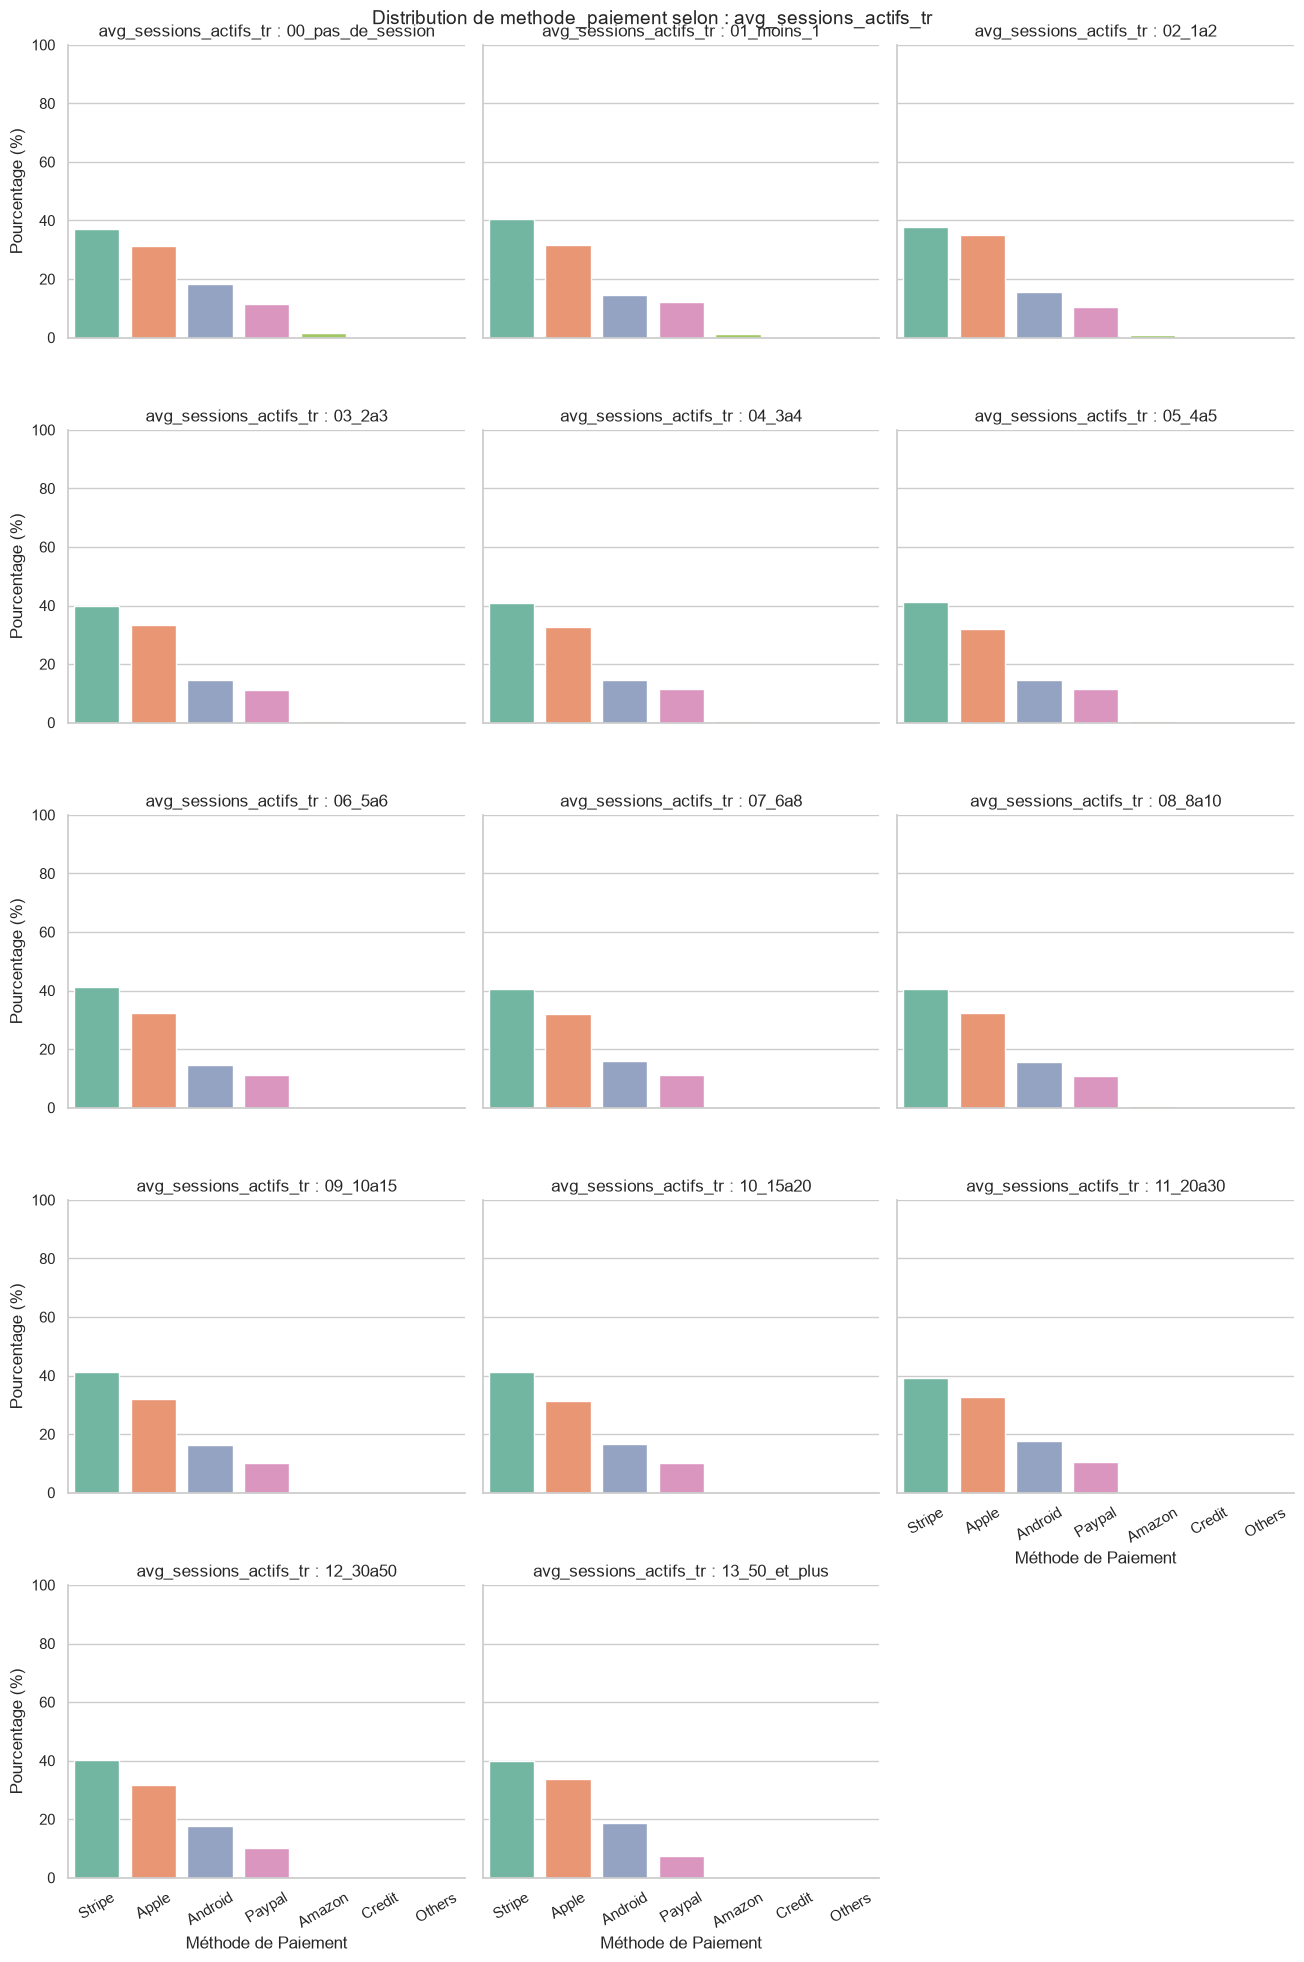

c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the s

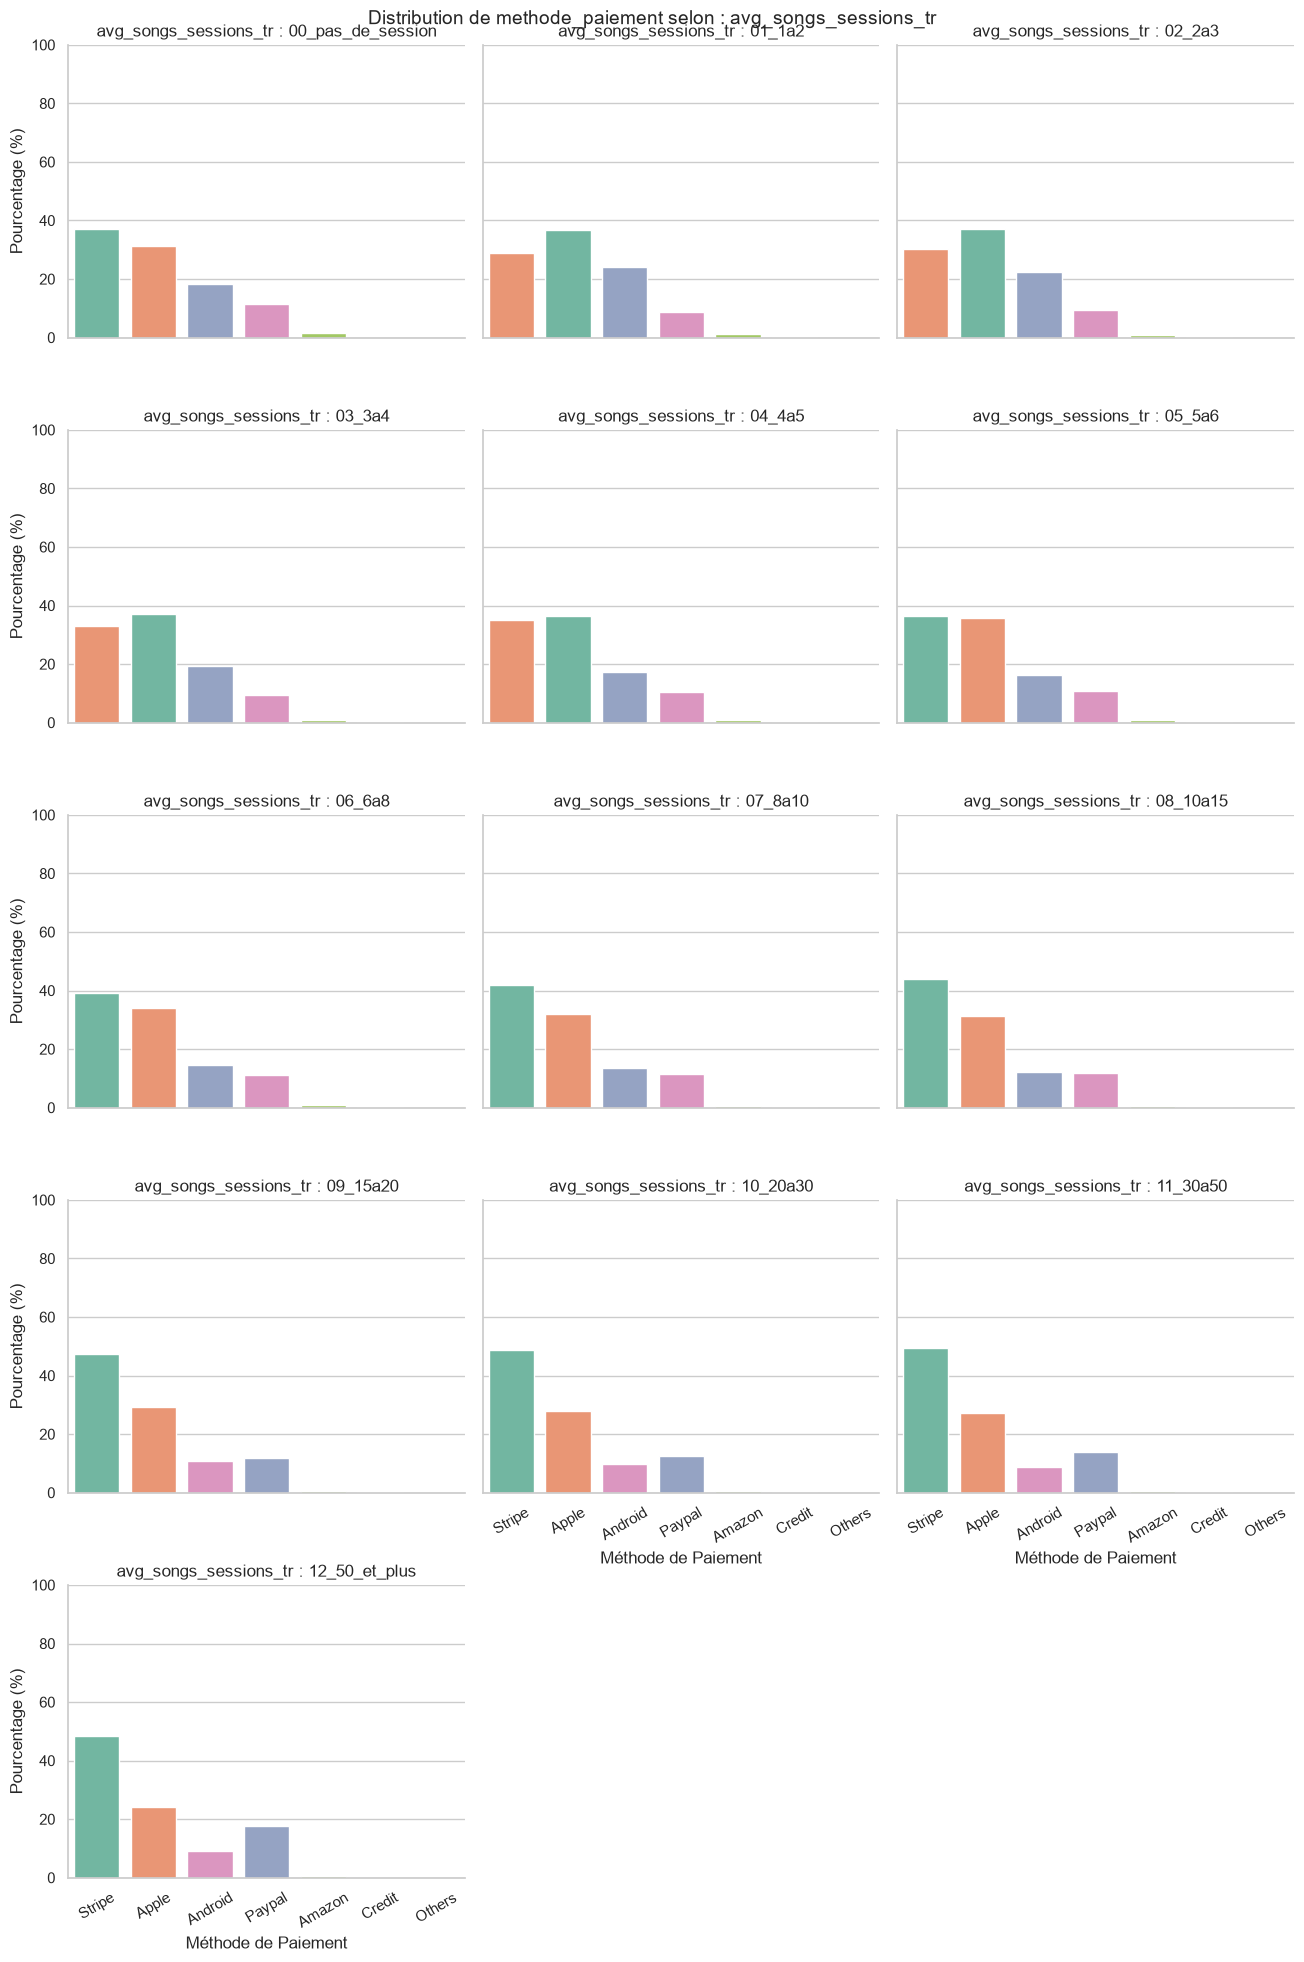

c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the s

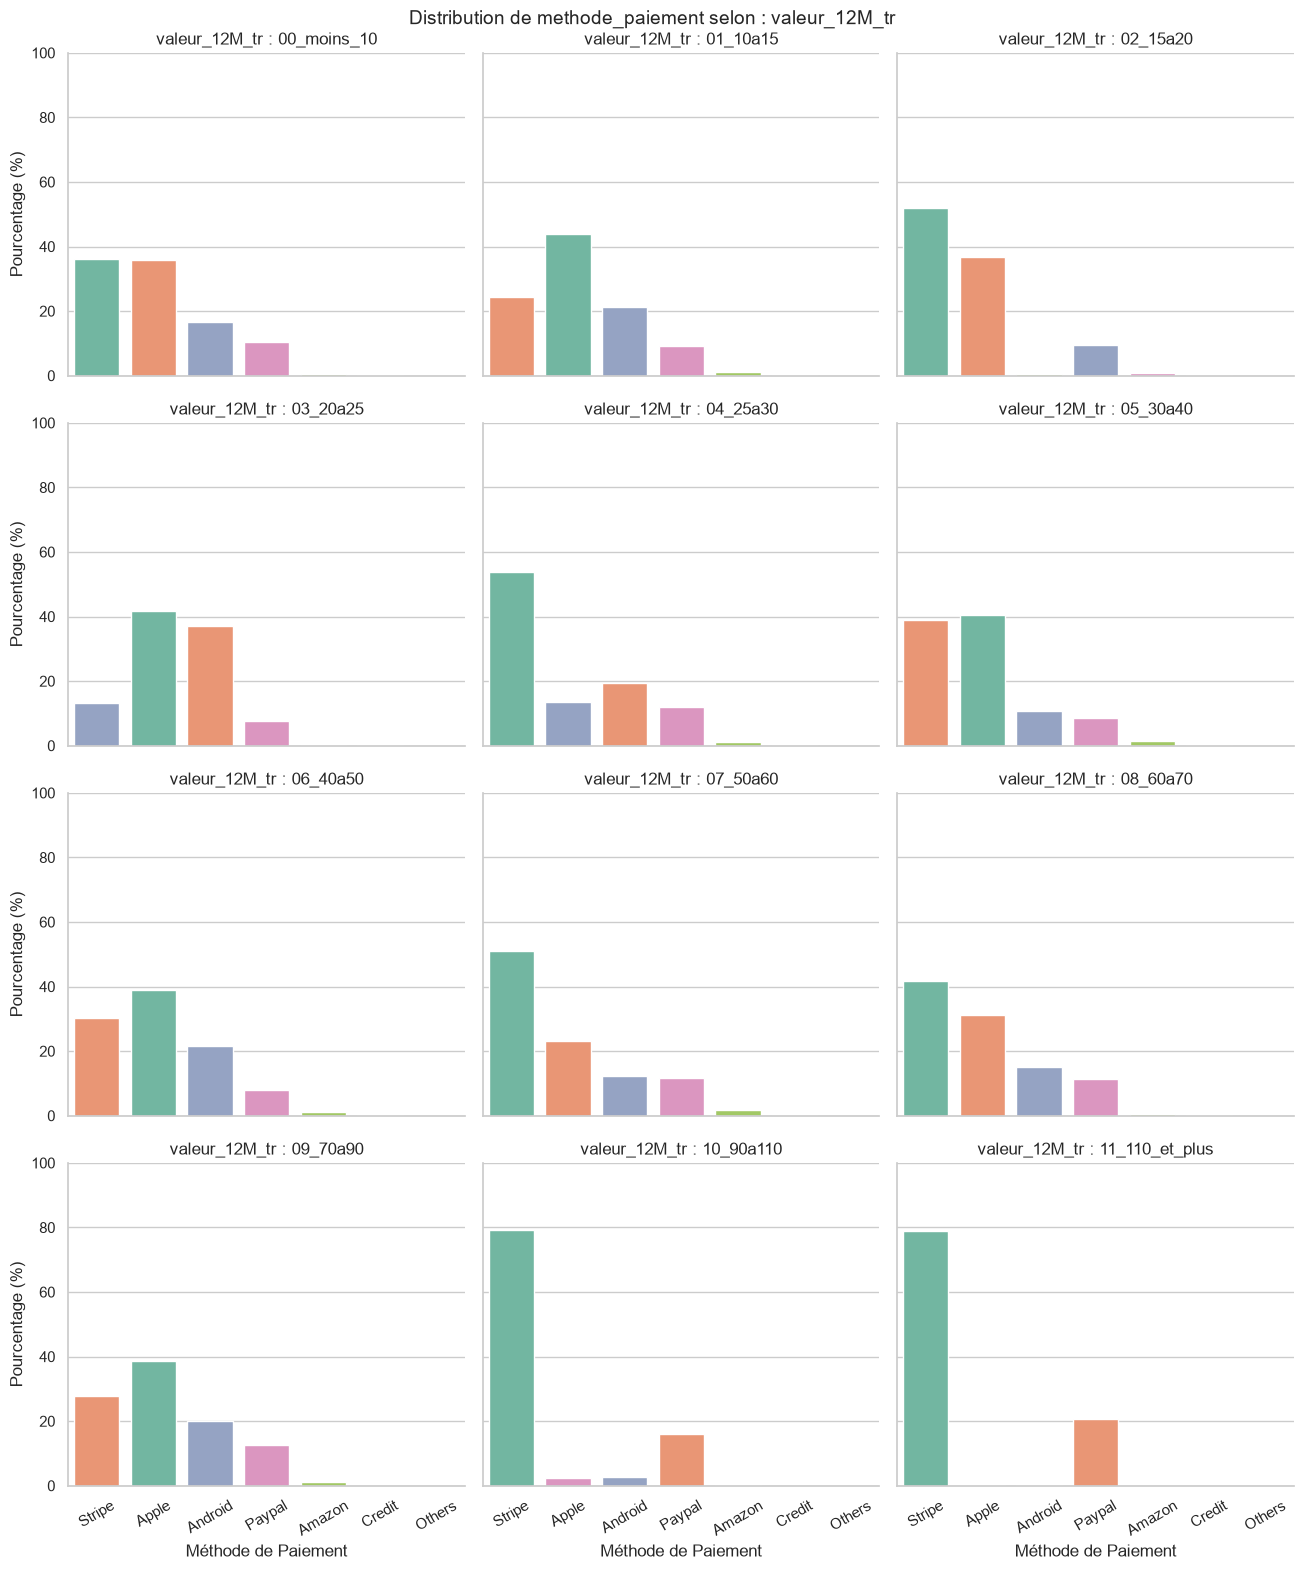

c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)


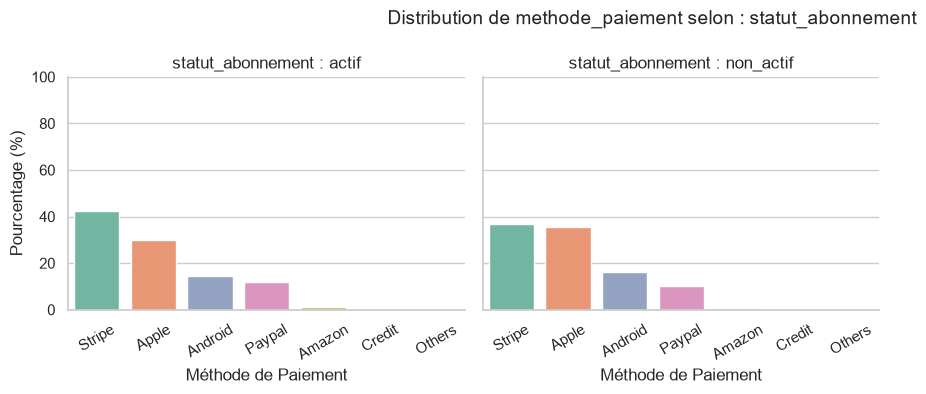

c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the s

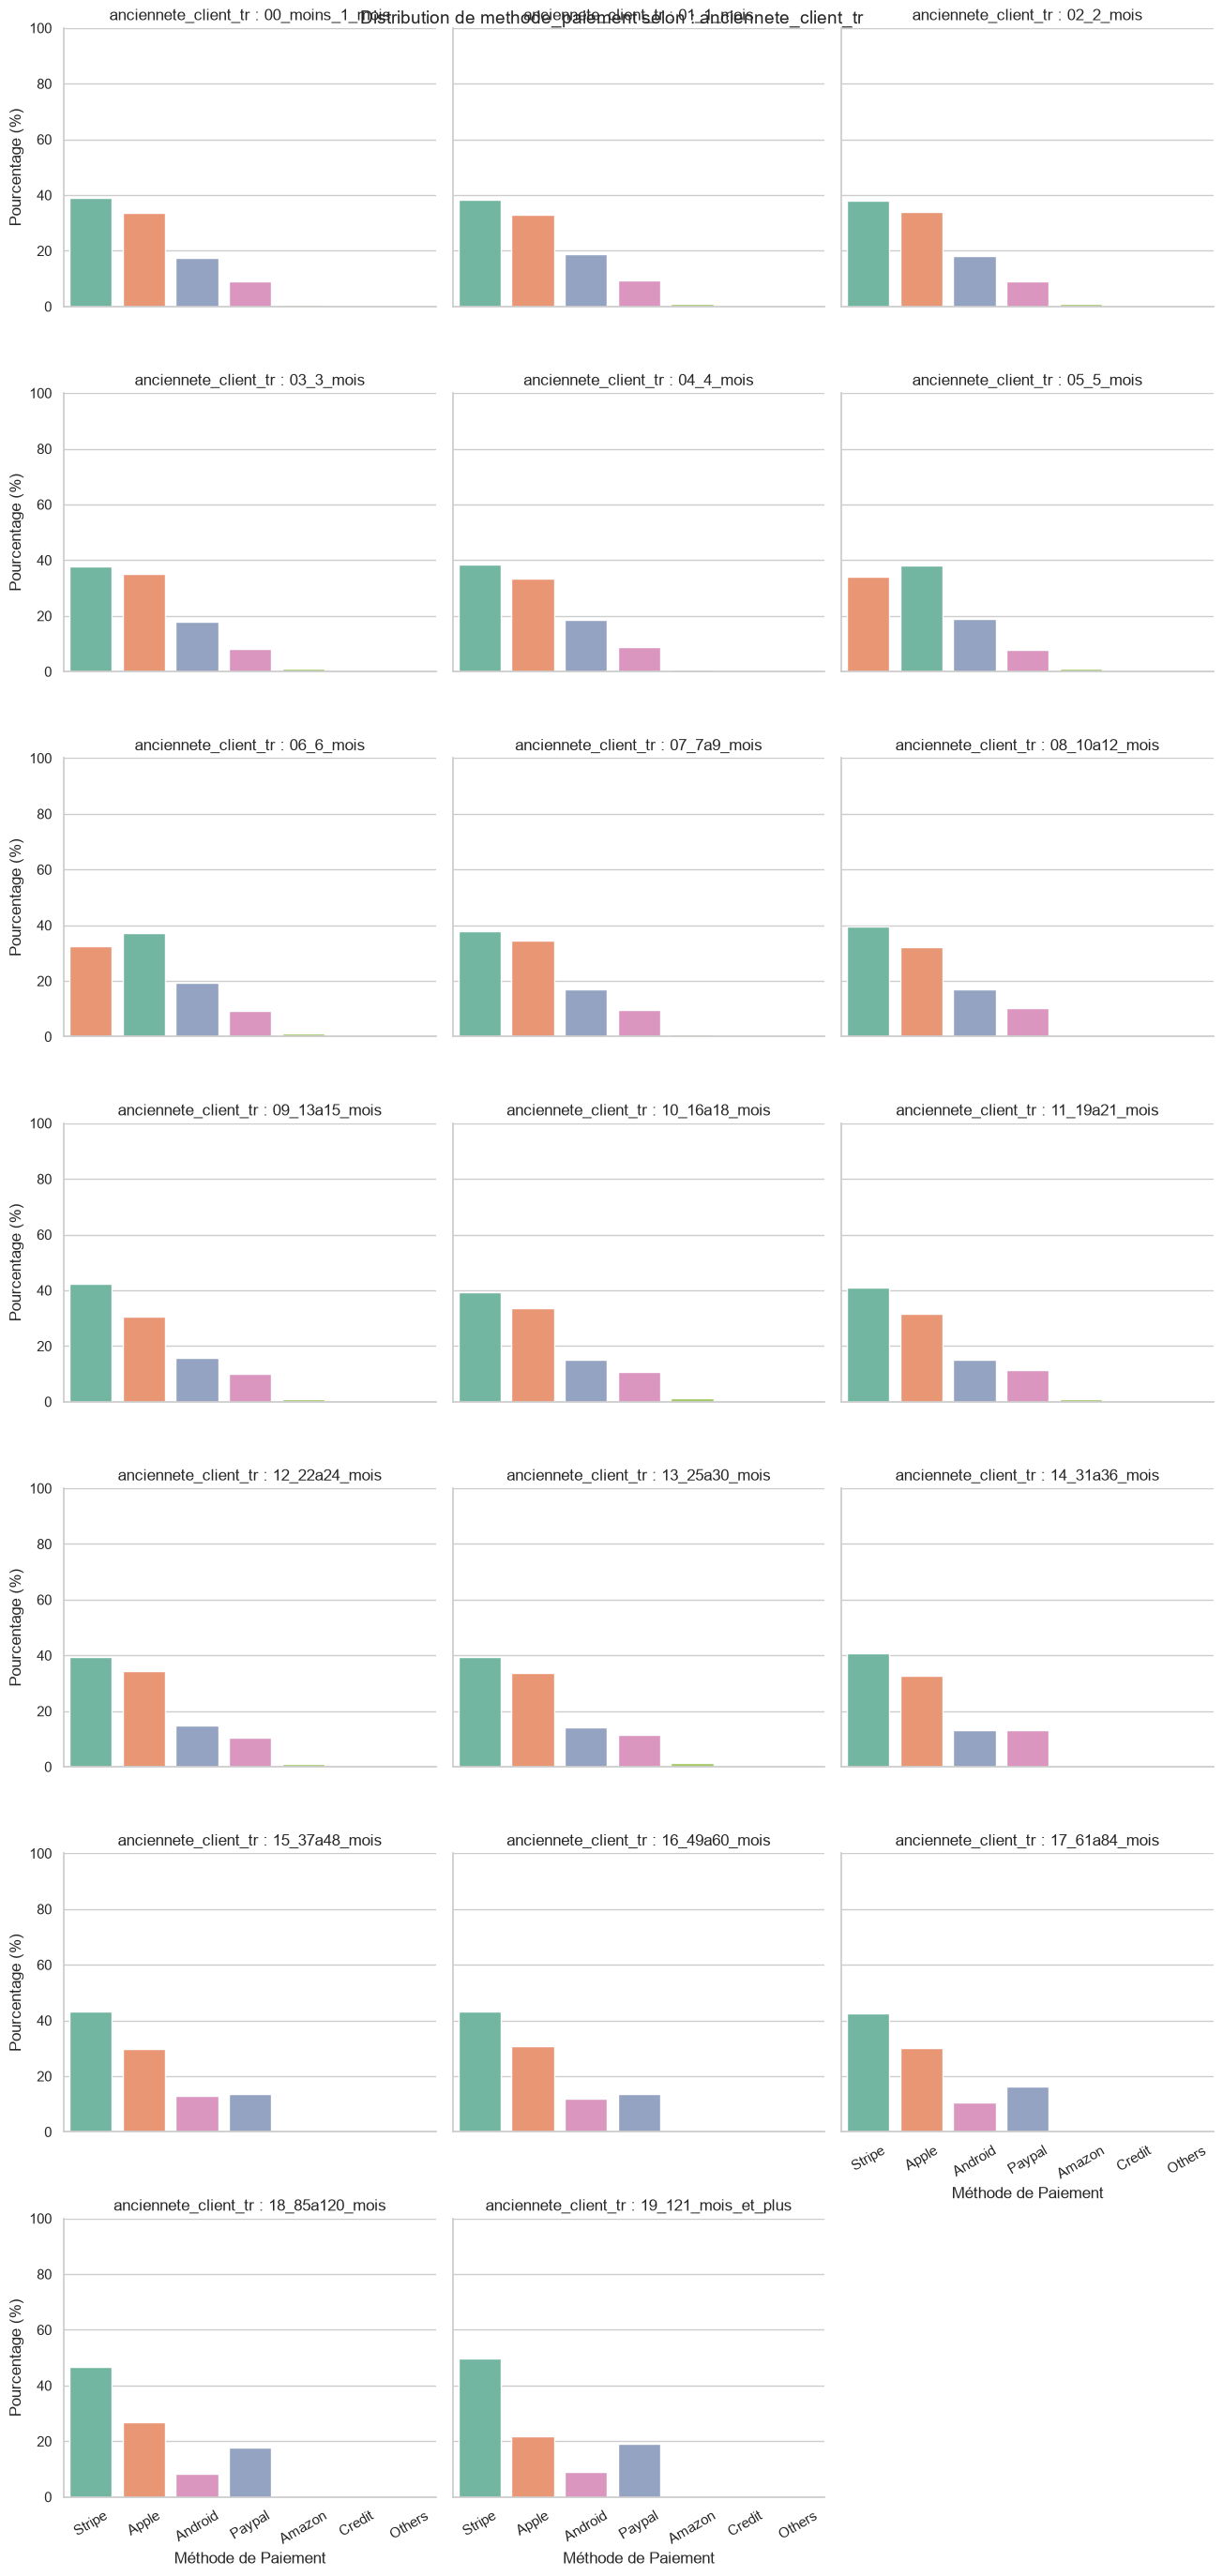

c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the s

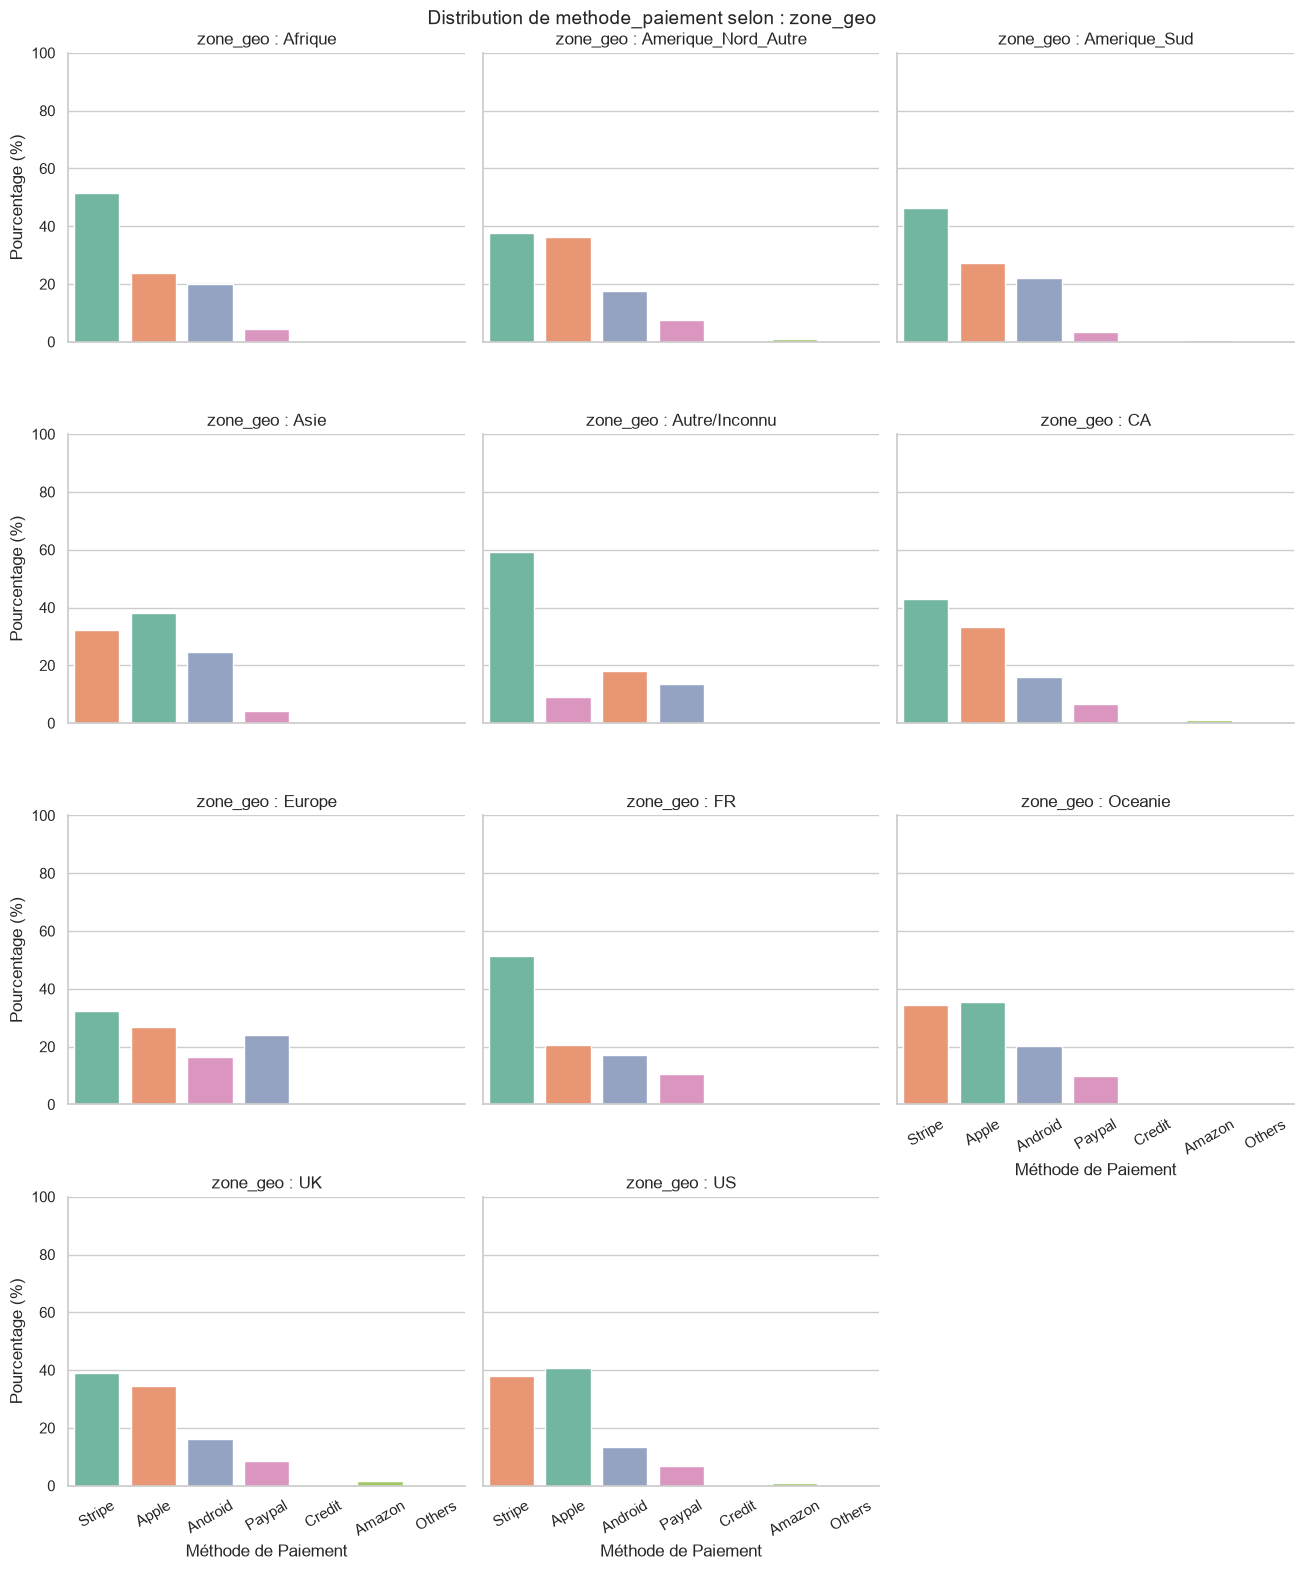

In [16]:
# 1. Distribution globale de référence : methode_paiement
plt.figure(figsize=(6, 4))
dist_globale_paiement = data['methode_paiement'].value_counts(normalize=True) * 100
sns.barplot(x=dist_globale_paiement.index, y=dist_globale_paiement.values, palette='Blues_d')
plt.title('Distribution Globale : methode_paiement (Référence)')
plt.ylabel('Pourcentage (%)')
plt.xlabel('Méthode de Paiement')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# 2. Liste des variables avec lesquelles croiser methode_paiement
liste_variables = [
    'avg_sessions_actifs_tr',
    'avg_songs_sessions_tr',
    'valeur_12M_tr',
    'statut_abonnement',
    'anciennete_client_tr',
    'zone_geo'
]

# 3. Boucle d'itération sur chaque variable
for var in liste_variables:
    # Calcul des proportions relatives de methode_paiement au sein de chaque modalité de 'var'
    df_prop = (
        data.groupby(var)['methode_paiement']
        .value_counts(normalize=True)
        .rename('pourcentage')
        .reset_index()
    )
    df_prop['pourcentage'] *= 100
    
    # Création de la grille de sous-graphiques (FacetGrid)
    g = sns.FacetGrid(df_prop, col=var, col_wrap=3, height=4, aspect=1.1)
    g.map_dataframe(sns.barplot, x='methode_paiement', y='pourcentage', palette='Set2')
    
    # Personnalisation visuelle
    g.set_axis_labels('Méthode de Paiement', 'Pourcentage (%)')
    g.set_titles(col_template=f'{var} : {{col_name}}')
    g.set(ylim=(0, 100))  # Échelle fixe à 100% pour observer les variations
    
    # Rotation des étiquettes
    for ax in g.axes.flat:
        ax.tick_params(axis='x', rotation=30)
        
    g.fig.subplots_adjust(top=0.85)
    g.fig.suptitle(f'Distribution de methode_paiement selon : {var}', fontsize=14)
    plt.tight_layout()
    plt.show()